# Jude et al. 2026: exploring the source data

Bimanual **QWERTY typing** iBCI. Two BrainGate2 participants attempt to type by making individual finger movements: **T17** (ALS, six Utah arrays in the left precentral gyrus, areas 6v, 55b and 6d) and **T18** (spinal-cord injury, six arrays in area 6d, four in the left hemisphere and two in the right). The source is the Dryad `.mat` blocks read **locally in place** (`scipy.io.loadmat`), one block per file, each a recording with many cued trials inside.

This notebook walks the raw layout: sessions and blocks, the per-block fields, the 10 ms-binned neural features, the per-array channel layout, the recording pauses, T17's microphone, the cues across task families and the online decoder configuration.

The setup cell builds the Study and calls `download()`, which fetches the data on the first run and returns immediately once the success file exists. It needs a Dryad API key, exported as `NEURALFETCH_DRYAD_TOKEN` or saved in a local `.env` file.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from neuralshed.datasets.jude_2026_speech import utils as speech
from neuralshed.datasets.jude_2026_typing import utils
from neuralshed.datasets.jude_2026_typing.study import Jude2026Typing
from neuralshed.datasets.utils import dataset_dir

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

# reads ./.env into os.environ
load_dotenv()

s = Jude2026Typing(path=dataset_dir("jude_2026_typing") / "data")
s.download()

# the extracted Data/ tree under the study folder
blocks_root = s.path / "Data"
sessions = utils.list_sessions(blocks_root)
print("data dir:", s.path)
print(len(sessions), "sessions across participants", utils.SUBJECTS)


def fingerprints(power):
    """Per 64-column group: within-group correlations and per-electrode medians of log power."""
    x = np.log1p(np.asarray(power, dtype=np.float32))
    n = (x.shape[0] // 10) * 10
    x = x[:n].reshape(-1, 10, x.shape[1]).mean(1)
    corr = np.corrcoef(x.T)
    med = np.median(x, axis=0)
    out = []
    for g in range(x.shape[1] // utils.CHANNELS_PER_ARRAY):
        cols = slice(g * utils.CHANNELS_PER_ARRAY, (g + 1) * utils.CHANNELS_PER_ARRAY)
        sub = corr[cols, cols]
        out.append((sub[~np.eye(len(sub), dtype=bool)], med[cols]))
    return out


def similarity(groups, reference):
    """(6, 6) mean of the correlation-structure and median-power agreement of each group pair."""
    return np.array(
        [
            [0.5 * np.corrcoef(sa, sb)[0, 1] + 0.5 * np.corrcoef(ma, mb)[0, 1] for sb, mb in reference]
            for sa, ma in groups
        ]
    )


def bins_of(bin_times, times_ns):
    """Nearest neural bin of each NSP timestamp."""
    return np.array([utils.bin_index(bin_times, t) for t in times_ns])

2026-10-12 16:36:59 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/jude_2026_typing/data/Jude2026Typing.


2026-10-12 16:37:00 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/jude_2026_typing/data/Jude2026Typing (skipped 0 non-owned items).


data dir: /Volumes/seagate_0/tether/datasets/jude_2026_typing/data/Jude2026Typing
19 sessions across participants ('T17', 'T18')


## 1. Sessions & blocks

One row per session: subject, date, post-implant day, recording-task folder, task blocks, excluded files, trials and the task families present (from the Dryad block tables, `utils.SESSION_BLOCKS`).

In [2]:
rows = []
for session in sessions:
    catalogued = utils.SESSION_BLOCKS[session]
    n_trials = 0
    for block in catalogued:
        n_trials += len(utils.get_trials(utils.block_path(session, block, blocks_root)))
    rows.append(
        {
            "session": session,
            "subject": utils.subject_of(session),
            "date": utils.session_date(session),
            "post_implant_day": utils.post_implant_day(session),
            "task_folder": utils.session_modality(session, blocks_root),
            "task_blocks": len(catalogued),
            "excluded": len(utils.EXCLUDED_BLOCKS.get(session, {})),
            "trials": n_trials,
            "task_families": ", ".join(sorted(set(catalogued.values()))),
        }
    )
sessions_df = pd.DataFrame(rows)
display(sessions_df)
print("task blocks:", sessions_df.task_blocks.sum(), "| trials:", sessions_df.trials.sum())

,session,subject,date,post_implant_day,task_folder,task_blocks,excluded,trials,task_families
0,t17.2024.04.24,T17,2024-04-24,55,brainToText,8,0,496,finger_movement
1,t17.2024.04.25,T17,2024-04-25,56,Typing,4,0,80,calibration
2,t17.2024.06.03,T17,2024-06-03,95,Typing,7,0,140,"calibration, sentence_copy"
3,t17.2024.06.04,T17,2024-06-04,96,Typing,9,1,120,"calibration, free_typing, sentence_copy"
4,t17.2024.06.05,T17,2024-06-05,97,Typing,5,0,79,"calibration, free_typing, sentence_copy"
5,t17.2024.06.13,T17,2024-06-13,105,Typing,2,0,40,calibration
6,t17.2024.07.09,T17,2024-07-09,131,Typing,10,0,93,"calibration, free_typing"
7,t17.2024.07.10,T17,2024-07-10,132,Typing,4,0,40,"calibration, free_typing"
8,t17.2024.07.22,T17,2024-07-22,144,Typing,5,0,76,"calibration, free_typing"
9,t18.2024.12.03,T18,2024-12-03,43,brainToText,6,3,327,finger_movement


task blocks: 160 | trials: 2649


### Excluded blocks

Every deposited file the Study skips, with its reason from `utils.EXCLUDED_BLOCKS` and `utils.DUPLICATE_FILES`, and the three blocks the Dryad README lists that `Data.zip` does not hold (`utils.NOT_DEPOSITED`).

In [3]:
rows = []
for session, blocks in utils.EXCLUDED_BLOCKS.items():
    for block, reason in blocks.items():
        path = utils.block_path(session, block, blocks_root)
        rows.append(
            {
                "session": session,
                "block": block,
                "file": path.name,
                "size_MB": round(path.stat().st_size / 1e6, 1),
                "reason": reason,
            }
        )
for session, files in utils.DUPLICATE_FILES.items():
    for name, reason in files.items():
        path = utils.session_dir(session, blocks_root) / name
        rows.append(
            {
                "session": session,
                "block": int(name.split("(")[1].split(")")[0]),
                "file": name,
                "size_MB": round(path.stat().st_size / 1e6, 1),
                "reason": reason,
            }
        )
for session, blocks in utils.NOT_DEPOSITED.items():
    for block in blocks:
        rows.append(
            {
                "session": session,
                "block": block,
                "file": "absent",
                "size_MB": None,
                "reason": "listed in the Dryad README, not in Data.zip",
            }
        )
pd.DataFrame(rows)

,session,block,file,size_MB,reason
0,t17.2024.06.04,7,20240604_164838_(7).mat,39.6,free-typing block with no recorded sentences
1,t18.2024.12.03,0,20241203_161511_(0).mat,14.5,"reference block, one DO_NOTHING trial, used to fit LRR and thresholds"
2,t18.2024.12.03,7,20241203_175112_(7).mat,14.5,"reference block, one DO_NOTHING trial, used to fit LRR and thresholds"
3,t18.2024.12.03,8,20241203_175718_(8).mat,14.5,"reference block, one DO_NOTHING trial, used to fit LRR and thresholds"
4,t18.2024.12.04,7,20241204_164727_(7).mat,347.8,"re-export of 20241204_163713_(7).mat, identical arrays"
5,t17.2024.06.03,1,absent,NaN,"listed in the Dryad README, not in Data.zip"
6,t17.2024.06.03,2,absent,NaN,"listed in the Dryad README, not in Data.zip"
7,t17.2024.06.03,3,absent,NaN,"listed in the Dryad README, not in Data.zip"


## 2. One block up close

Each `.mat` file is one block: two 10 ms-binned neural-feature arrays `(n_bins, 384)` plus per-trial cues and NSP timing. We pick a T18 sentence-copy block.

In [4]:
# a sentence-copy block (10 trials)
session = "t18.2025.01.14"
block = 3
path = utils.block_path(session, block, blocks_root)
print(f"{session} block {block} -> {path.name} ({path.stat().st_size / 1e6:.0f} MB)")
print("task family:", utils.task_of(session, block), "| loop:", utils.loop_type(session, block))
print("subject:", utils.subject_of(session), "| n_channels:", utils.n_channels(path))
description = utils.read_block(path, fields=["block_description"])["block_description"]
print("block_description:", repr(str(description)))

tx, sbp = utils.get_neural(path)
print("threshold_crossings:", tx.shape, tx.dtype)
print("spike_band_power   :", sbp.shape, sbp.dtype)
seconds = tx.shape[0] / utils.FS_NEURAL
print(f"bins: {tx.shape[0]} ({seconds:.0f} s at {utils.FS_NEURAL} Hz, {utils.NEURAL_BIN_SIZE_MS} ms bins)")

t18.2025.01.14 block 3 -> 20250114_133746_(3).mat (129 MB)
task family: sentence_copy | loop: closed
subject: T18 | n_channels: 384
block_description: 'Runs a closed loop brianToText block then runs the parameterUpdater script to get thresholds and lrr weights, online RNN training in background after each trial.'
threshold_crossings: (54384, 384) int16
spike_band_power   : (54384, 384) float32
bins: 54384 (544 s at 100 Hz, 10 ms bins)


### Trial table

One row per cue. `trial_start_ns`, `go_cue_ns` and `trial_end_ns` are NSP timestamps in nanoseconds that place each trial on the neural bins. `paused` and `timed_out` are zero on every trial of the deposit.

In [5]:
trials = utils.get_trials(path)
print(len(trials), "trials |", int(trials.paused.sum()), "paused,", int(trials.timed_out.sum()), "timed out")
print("columns:", list(trials.columns))
trials[["cue", "delay_ms", "iti_ms", "trial_start_ns", "go_cue_ns", "trial_end_ns"]].head()

10 trials | 0 paused, 0 timed out
columns: ['cue', 'go_cue_ns', 'trial_end_ns', 'trial_start_ns', 'delay_ms', 'iti_ms', 'paused', 'timed_out']


,cue,delay_ms,iti_ms,trial_start_ns,go_cue_ns,trial_end_ns
0,She can't run in the morning.,4000.0,3000.0,1.712699e+18,1.712699e+18,1.712699e+18
1,And they're very dedicated to that.,4000.0,3000.0,1.712699e+18,1.712699e+18,1.712699e+18
2,The same patterns of behavior.,4000.0,3000.0,1.712699e+18,1.712699e+18,1.712699e+18
3,Talk about asking for trouble.,4000.0,3000.0,1.712699e+18,1.712699e+18,1.712699e+18
4,What was the last car repair you had.,4000.0,3000.0,1.712699e+18,1.712699e+18,1.712699e+18


### Trial timing across task families

Over every catalogued block, the delay runs from trial start to the go cue, the go window from the go cue to the trial end, and the gap from a trial end to the next trial start, all on the neural bins. Finger-movement trials are short and evenly spaced, sentence trials last tens of seconds, and free typing has no cue to show during its delay.

In [6]:
rows = []
for session, blocks in utils.SESSION_BLOCKS.items():
    for block, family in blocks.items():
        p = utils.block_path(session, block, blocks_root)
        bin_times = utils.get_bin_times_ns(p)
        tr = utils.get_trials(p)
        start = bins_of(bin_times, tr.trial_start_ns)
        go = bins_of(bin_times, tr.go_cue_ns)
        end = bins_of(bin_times, tr.trial_end_ns)
        gap = np.append(start[1:] - end[:-1], np.nan)
        rows.append(
            pd.DataFrame(
                {
                    "subject": utils.subject_of(session),
                    "task_family": family,
                    "delay_s": (go - start) / utils.FS_NEURAL,
                    "go_s": (end - go) / utils.FS_NEURAL,
                    "gap_s": gap / utils.FS_NEURAL,
                }
            )
        )
timing = pd.concat(rows, ignore_index=True)

summary = timing.groupby(["subject", "task_family"]).agg(
    trials=("delay_s", "size"),
    delay_median=("delay_s", "median"),
    delay_min=("delay_s", "min"),
    delay_max=("delay_s", "max"),
    go_median=("go_s", "median"),
    gap_median=("gap_s", "median"),
)
summary.round(2)

trials  delay_median  delay_min  delay_max  go_median  gap_median
subject task_family                                                                       
T17     calibration         503          4.00       4.00       6.51      47.75        0.00
        finger_movement     496          3.96       1.50       4.49       2.50        2.50
        free_typing         105          3.85       0.00      65.59      53.84        5.54
        sentence_copy        60          4.00       4.00       4.01      49.14        0.77
T18     calibration         270          4.01       3.99       8.01      36.00        1.00
        finger_movement     451          2.02       1.50       2.50       2.50        2.50
        free_typing          17         10.71       3.60      23.84      41.64        3.50
        handwriting         122          5.00       5.00       5.01      36.00        1.00
        sentence_copy       625          7.00       4.00       9.01      25.83        3.19

### Per-array channel layout

Both participants store all **384** channels (six 64-channel arrays, one block of 64 columns each). The column-to-array map differs per participant (from the authors' per-array FVAF figure notebooks, see the README's Channel order):

In [7]:
table = {}
for subject in utils.SUBJECTS:
    table[subject] = [f"{name} ({hemisphere}, {area})" for name, hemisphere, area in utils.ARRAYS[subject]]
columns = [f"{lo}-{hi - 1}" for lo, hi in utils.array_channels("T17").values()]
pd.DataFrame(table, index=columns).rename_axis("columns")

,T17,T18
columns,,
0-63,"ventral_6v (left, 6v)","mid_ventral_6d (left, 6d)"
64-127,"dorsal_6v (left, 6v)","ventral_6d (left, 6d)"
128-191,"ventral_55b (left, 55b)","dorsal_6d (left, 6d)"
192-255,"dorsal_55b (left, 55b)","mid_dorsal_6d (left, 6d)"
256-319,"ventral_6d (left, 6d)","lateral_6d (right, 6d)"
320-383,"dorsal_6d (left, 6d)","medial_6d (right, 6d)"


### T17 column groups against jude_2026_speech

T17 is the participant of `jude_2026_speech`, recorded through the same arrays. Each 64-column group of three typing blocks is matched to the six groups of a late speech block in that package's Study order, on the within-group correlation structure and the per-electrode median spike-band power. Every group matches the group of the same name.

In [8]:
field = "binned_neural_spike_band_power"
names = [name for name, _, _ in utils.ARRAYS["T17"]]

# a late jude_2026_speech block, in that package's Study order
ref_session = "t17.2024.05.28"
ref_block = 6
ref = speech.read_block(speech.block_path(ref_session, ref_block), fields=[field])[field]
ref = fingerprints(speech.to_study_order(np.asarray(ref), ref_session))

matches = {}
for session, block in [("t17.2024.04.25", 1), ("t17.2024.06.03", 4), ("t17.2024.06.13", 7)]:
    d = utils.read_block(utils.block_path(session, block, blocks_root), fields=[field])
    sim = similarity(fingerprints(d[field]), ref)
    matches[f"{session} b{block}"] = [names[k] for k in sim.argmax(1)]
pd.DataFrame(matches, index=names).rename_axis("typing column group")

,t17.2024.04.25 b1,t17.2024.06.03 b4,t17.2024.06.13 b7
typing column group,,,
ventral_6v,ventral_6v,ventral_6v,ventral_6v
dorsal_6v,dorsal_6v,dorsal_6v,dorsal_6v
ventral_55b,ventral_55b,ventral_55b,ventral_55b
dorsal_55b,dorsal_55b,dorsal_55b,dorsal_55b
ventral_6d,ventral_6d,ventral_6d,ventral_6d
dorsal_6d,dorsal_6d,dorsal_6d,dorsal_6d


### Neural features for one trial

Threshold crossings and spike-band power for the first trial's window from the go cue to the trial end (capped to the first 12 s for display). The participant types the cued sentence character by character with attempted finger movements, so trials are long.

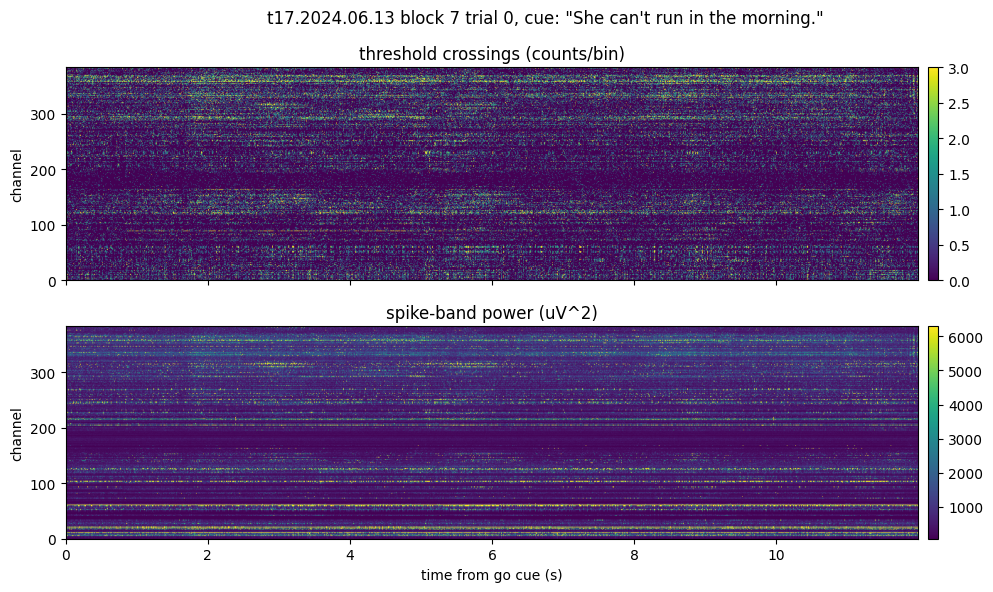

In [9]:
bin_times = utils.get_bin_times_ns(path)
i = 0
a, b = utils.trial_window(bin_times, trials.go_cue_ns[i], trials.trial_end_ns[i])
# cap to 12 s for display
b = min(b, a + 1200)
seg_tx = tx[a:b].T
seg_sbp = sbp[a:b].T
t = np.arange(seg_tx.shape[1]) / utils.FS_NEURAL

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
panels = [
    (ax[0], seg_tx, "threshold crossings (counts/bin)"),
    (ax[1], seg_sbp, "spike-band power (uV^2)"),
]
for axis, data, name in panels:
    im = axis.imshow(
        data,
        aspect="auto",
        origin="lower",
        cmap="viridis",
        vmin=np.percentile(data, 2),
        vmax=np.percentile(data, 98),
        extent=[0, t[-1], 0, utils.N_CHANNELS],
    )
    axis.set_ylabel("channel")
    axis.set_title(name)
    fig.colorbar(im, ax=axis, pad=0.01)
ax[1].set_xlabel("time from go cue (s)")
fig.suptitle(f'{session} block {block} trial {i}, cue: "{trials.cue[i]}"')
plt.tight_layout()
plt.show()

### Recording pauses

In 11 blocks the NSP clock jumps between two consecutive bins, with no bins recorded in between. `utils.clock_breaks` finds the jumps. The Study keeps every trial window and `Intertrial` row on one side of a pause.

,session,block,task_family,recorded_s,pauses,pause_s
0,t17.2024.06.04,9,free_typing,847,4,"[162.2, 126.3, 147.5, 59.5]"
1,t17.2024.06.04,10,free_typing,1002,8,"[42.1, 167.1, 29.7, 43.1, 19.7, 11.0, 84.6, 53.5]"
2,t17.2024.06.04,11,free_typing,851,1,[42.2]
3,t17.2024.06.05,3,free_typing,906,3,"[16.7, 72.7, 14.3]"
4,t17.2024.07.09,4,free_typing,151,7,"[44.4, 47.4, 70.6, 119.8, 62.8, 59.4, 61.0]"
5,t17.2024.07.09,10,free_typing,374,3,"[80.3, 76.9, 42.3]"
6,t17.2024.07.10,3,free_typing,455,4,"[5.9, 30.7, 12.7, 16.5]"
7,t17.2024.07.10,4,free_typing,451,1,[67.3]
8,t17.2024.07.22,4,free_typing,760,11,"[0.0, 0.9, 69.5, 136.9, 68.1, 20.6, 43.6, 33.0, 32.6, 26.7, 8.6]"
9,t17.2024.07.22,5,free_typing,440,5,"[0.0, 0.8, 274.4, 49.8, 20.2]"


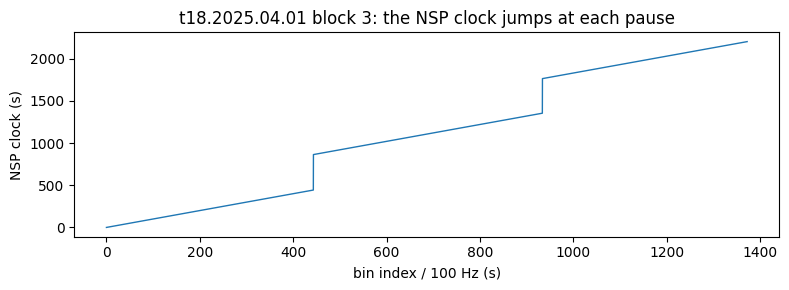

In [10]:
rows = []
for session, blocks in utils.SESSION_BLOCKS.items():
    for block, family in blocks.items():
        bin_times = utils.get_bin_times_ns(utils.block_path(session, block, blocks_root))
        breaks = utils.clock_breaks(bin_times)
        if len(breaks) == 0:
            continue
        pauses = np.diff(bin_times)[breaks] / 1e9
        rows.append(
            {
                "session": session,
                "block": block,
                "task_family": family,
                "recorded_s": round(len(bin_times) / utils.FS_NEURAL),
                "pauses": len(breaks),
                "pause_s": np.round(pauses, 1).tolist(),
            }
        )
display(pd.DataFrame(rows))

# handwriting block 3: three 10-sentence segments
hw = utils.get_bin_times_ns(utils.block_path("t18.2025.04.01", 3, blocks_root))
plt.figure(figsize=(8, 3))
plt.plot(np.arange(len(hw)) / utils.FS_NEURAL, (hw - hw[0]) / 1e9, lw=1)
plt.xlabel("bin index / 100 Hz (s)")
plt.ylabel("NSP clock (s)")
plt.title("t18.2025.04.01 block 3: the NSP clock jumps at each pause")
plt.tight_layout()
plt.show()

## 3. Microphone audio (T17 only)

T17 (anarthric) has a 30 kHz microphone per block, T18 blocks carry none. `utils.get_audio` returns `None` for T18.

T17 block: 20240425_135520_(1).mat -> audio (40510230,) at 30000 Hz
T18 block: 20250114_133746_(3).mat -> audio None


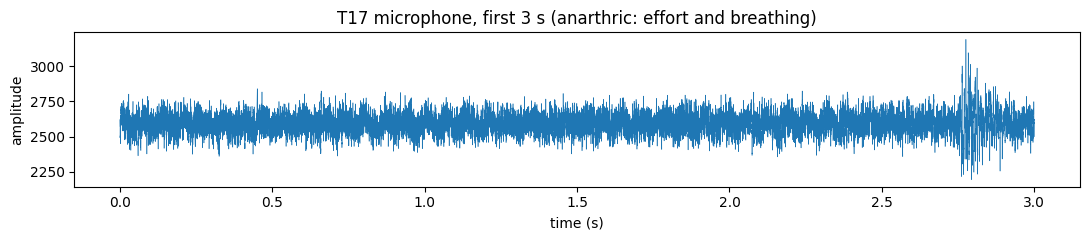

In [11]:
t17_path = utils.block_path("t17.2024.04.25", 1, blocks_root)
audio, fs = utils.get_audio(t17_path)
print("T17 block:", t17_path.name, "-> audio", audio.shape, "at", fs, "Hz")
t18_audio, _ = utils.get_audio(path)
print("T18 block:", path.name, "-> audio", t18_audio)

# first 3 s
snip = audio[: fs * 3].astype(np.float32)
plt.figure(figsize=(11, 2.5))
plt.plot(np.arange(len(snip)) / fs, snip, lw=0.4)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("T17 microphone, first 3 s (anarthric: effort and breathing)")
plt.tight_layout()
plt.show()

## 4. Task variety: cues across families

The `cue` field means different things per task family: a finger-movement or key instruction (isolated-movement blocks) or a sentence to type (calibration, sentence copy, free typing, handwriting). Handwriting cues encode spaces as `>` and the end as `~`, which `utils.get_trials` removes.

In [12]:
fam_examples = {
    "finger_movement": ("t18.2024.12.03", 2),
    "finger_movement (key cues)": ("t18.2024.12.04", 2),
    "calibration": ("t17.2024.04.25", 1),
    "sentence_copy": ("t18.2024.12.05", 3),
    "free_typing": ("t17.2024.06.04", 8),
    "handwriting": ("t18.2025.04.01", 4),
}
rows = []
for name, (session_, block_) in fam_examples.items():
    modality = "handwriting" if name == "handwriting" else "typing"
    tr = utils.get_trials(utils.block_path(session_, block_, blocks_root), modality=modality)
    rows.append(
        {
            "task_family": name,
            "session": session_,
            "block": block_,
            "subject": utils.subject_of(session_),
            "n_trials": len(tr),
            "distinct_cues": tr.cue.nunique(),
            "example_cue": tr.cue.iloc[0][:48],
        }
    )
pd.DataFrame(rows)

,task_family,session,block,subject,n_trials,distinct_cues,example_cue
0,finger_movement,t18.2024.12.03,2,T18,62,31,DO NOTHING
1,finger_movement (key cues),t18.2024.12.04,2,T18,62,31,M
2,calibration,t17.2024.04.25,1,T17,20,20,Is it going outside?
3,sentence_copy,t18.2024.12.05,3,T18,3,3,Depending on where you live.
4,free_typing,t17.2024.06.04,8,T17,7,7,I like the new haircut.
5,handwriting,t18.2025.04.01,4,T18,10,10,join sides and base with slip and reinforce with


### Keyboard codes

`utils.CUE_CODES` gives each finger-movement condition one class id from the keyboard layout: 0 for rest, then 1-30 in keyboard order (top row Q-P, middle row A-?, bottom row Z-.). The movement cue and the key cue of the same key share the id.

In [13]:
rows = []
for code, movement in utils.MOVEMENTS.items():
    key_cue = [c for c, v in utils.CUE_CODES.items() if v == code and c != movement]
    rows.append({"code": code, "movement cue": movement, "key cue": ", ".join(key_cue)})
pd.DataFrame(rows).set_index("code")

,movement cue,key cue
code,,
0,DO NOTHING,DO_NOTHING
1,LEFT PINKY - Extend Upwards,Q
2,LEFT RING - Extend Upwards,W
3,LEFT MIDDLE - Extend Upwards,E
4,LEFT INDEX - Extend Upwards,R
5,LEFT THUMB - Extend Upwards,T
6,RIGHT THUMB - Extend Upwards,Y
7,RIGHT INDEX - Extend Upwards,U
8,RIGHT MIDDLE - Extend Upwards,I


## 5. Online decoder configuration

Closed-loop blocks store what the online decoder ran with. `norm_channel_means` holds one row per normalization update, one column per feature (crossings and power stacked), and `decoder_logit_output` holds 41 logits per row on the `decoder_output_redis_clock`. The table gives, per session and family, the normalization width, how many logit columns are ever non-zero, the share of all-zero rows and the median step between non-zero rows.

In [14]:
rows = []
for session, blocks in utils.SESSION_BLOCKS.items():
    for block, family in blocks.items():
        if utils.loop_type(session, block) != "closed":
            continue
        d = utils.read_block(
            utils.block_path(session, block, blocks_root),
            fields=["norm_channel_means", "decoder_logit_output", "decoder_output_redis_clock"],
        )
        norm = np.atleast_2d(np.asarray(d["norm_channel_means"]))
        logits = np.asarray(d["decoder_logit_output"])
        clock = np.asarray(d["decoder_output_redis_clock"], dtype=np.float64).ravel()
        live = np.abs(logits).sum(1) > 0
        rows.append(
            {
                "session": session,
                "task_family": family,
                "norm_width": norm.shape[-1],
                "used_columns": int((np.abs(logits).sum(0) > 0).sum()),
                "zero_rows": 1 - live.mean(),
                "live_step_ms": np.median(np.diff(clock[live])),
            }
        )
decoder = pd.DataFrame(rows)
decoder.groupby(["session", "task_family"]).agg(
    blocks=("norm_width", "size"),
    norm_width=("norm_width", lambda w: sorted(set(w))),
    used_columns=("used_columns", "max"),
    zero_rows=("zero_rows", "median"),
    live_step_ms=("live_step_ms", "median"),
).round(2)

blocks norm_width  used_columns  zero_rows  live_step_ms
session        task_family                                                            
t17.2024.06.03 sentence_copy       1      [256]            31       0.50          80.0
t17.2024.06.04 free_typing         4      [512]            31       0.47          80.0
               sentence_copy       1      [512]            31       0.50          80.0
t17.2024.06.05 free_typing         1      [512]            31       0.50          80.0
               sentence_copy       1      [512]            31       0.50          80.0
t17.2024.07.09 free_typing         6      [512]            31       0.50          80.0
t17.2024.07.10 free_typing         2      [512]            31       0.50          80.0
t17.2024.07.22 free_typing         2      [512]            31       0.39          80.0
t18.2024.12.05 free_typing         1      [768]            31       0.50          98.5
               sentence_copy       3      [768]            31       0.50         160.0
t18.2025.01.14 sentence_copy       9      [768]            31       0.50         100.0
t18.2025.01.15 sentence_copy       9      [768]            31       0.50         140.0
t18.2025.01.21 sentence_copy       8      [768]            31       0.50         120.0
t18.2025.01.22 sentence_copy      10      [768]            31       0.50         120.0
t18.2025.02.04 free_typing         1      [768]            31       0.50         120.0
               sentence_copy      10      [768]            31       0.50         120.0
t18.2025.02.05 sentence_copy      13      [768]            31       0.50         120.0
t18.2025.04.01 handwriting         1      [768]            31       0.50         320.0

## Summary

- **Layout:** `data/Jude2026Typing/Data/{t17,t18}/<session>/<Typing|brainToText|Handwriting>/RedisMat/*.mat`, one block per file. 160 task blocks enter the Study, and 5 files are excluded or duplicates. `utils` discovers and reads them.
- **Neural:** two 10 ms-binned (100 Hz) feature streams, `threshold_crossings` (int16) and `spike_band_power` (float32), `(n_bins, 384)` for both participants in six 64-column arrays. The online decoder used 256 or 512 features for T17 and 768 for T18, and the stored arrays are always 384 channels.
- **Recording pauses:** 11 blocks hold 49 pauses where the NSP clock jumps with no bins in between.
- **Cues:** per-trial sentence (typing, handwriting) or finger-movement and key instructions, windowed by NSP timing. Task family comes from the Dryad block tables and the loop type from each file's `block_description`. A movement cue and its key cue share one class id in `utils.CUE_CODES`.
- **Audio:** 30 kHz microphone for T17 only (anarthric).

Next: `02_explore_study.ipynb` standardizes these into neuralset events.